# Decision Trees: Building, Understanding, and Evaluating Classifiers

**Upper-level Artificial Intelligence / Machine Learning Lab**

**Estimated time:** 90–120 minutes  
**Tools:** Python, pandas, matplotlib, scikit-learn, Jupyter

## Lab overview

In this lab, you will build a decision-tree classifier using the Wisconsin Breast Cancer dataset. You will investigate how trees choose splits, compare Gini impurity with entropy, visualize a trained tree, observe overfitting, experiment with pruning, and interpret model performance.

The dataset contains measurements computed from digitized images of breast mass samples. The task is to classify each sample as **malignant** or **benign**. This is an educational exercise, not a clinical diagnostic system.

## Learning objectives

By the end of the lab, you should be able to:

1. Explain how a decision tree makes predictions.
2. Calculate and interpret Gini impurity and entropy.
3. Explain how a tree evaluates candidate splits.
4. Train and visualize a decision tree with scikit-learn.
5. Identify overfitting by comparing training and test performance.
6. Experiment with depth limits and cost-complexity pruning.
7. Interpret feature importance and a confusion matrix.
8. Discuss the strengths and limitations of decision trees.

## How to complete the lab

Run the notebook cells in order. Some cells ask you to change a parameter, compare results, or write a short explanation. Record your answers in the response areas. Do not simply report numbers: explain what they mean.

**Suggested submission:** This completed notebook, including code, plots, and written responses.


## Activity 0 — Setup and imports

We will use scikit-learn's built-in dataset, so no separate data download is required.

Run the following cell. If an import fails, install the missing package in your Python environment (for example, `pip install scikit-learn pandas matplotlib`).


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

RANDOM_STATE = 42

print("Setup complete.")


Setup complete.


## Activity 1 — Explore the dataset

The dataset has 30 numeric features describing characteristics of cell nuclei. The target contains two classes. In scikit-learn's encoding, the target names are `malignant` and `benign`; the numeric labels correspond to the order shown by `data.target_names`.

First, load and inspect the data.


In [2]:
data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="target")

print("Number of observations:", X.shape[0])
print("Number of features:", X.shape[1])
print("Target names:", data.target_names)

display(X.head())


Number of observations: 569
Number of features: 30
Target names: ['malignant' 'benign']


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [3]:
print("Class counts:")
print(y.value_counts().sort_index().rename(index=dict(enumerate(data.target_names))))

print("\nFeature summary:")
display(X.describe().T)


Class counts:
target
malignant    212
benign       357
Name: count, dtype: int64

Feature summary:


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


### Questions — Activity 1

1. How many observations and features are in the dataset?
2. How many examples belong to each class? Is the dataset perfectly balanced?
3. Pick three features that you think might help distinguish malignant from benign samples. Explain your choices.
4. Why should we keep a separate test set rather than evaluate a model only on the data used to train it?

**Your answers:**

1. 569 observations with 30 features
2. 212 malignant, 357 benign. It is not perfectly balanaced
3. 3 features that would help distinguish malignant from benign might be the 
4. To prevent over fitting, generalize better to new unseen data


## Activity 2 — How decision trees measure a good split

A decision tree makes a prediction by asking a sequence of questions about input features. Each question divides the data into child groups, called **nodes**. The tree prefers splits that make the resulting groups more homogeneous—that is, groups in which observations mostly belong to one class.

### 2.1 What is impurity?

**Impurity** describes how mixed the class labels are within a node.

Imagine a node containing 10 tumor samples:

- 10 benign and 0 malignant: the node is completely pure.
- 8 benign and 2 malignant: the node is mostly one class, but still mixed.
- 5 benign and 5 malignant: the node is maximally mixed for a two-class problem.

A pure node has impurity **0**. A node with a balanced mix of classes has higher impurity.

### 2.2 Gini impurity

Gini impurity estimates the chance of incorrectly labeling an observation if we randomly assign a class label according to the class proportions in that node.

\[
Gini = 1 - \sum_{i=1}^{K} p_i^2
\]

Here, \(p_i\) is the proportion of observations belonging to class \(i\), and \(K\) is the number of classes.

For a node with 8 benign and 2 malignant samples:

\[
Gini = 1 - (0.8^2 + 0.2^2) = 1 - (0.64 + 0.04) = 0.32
\]

For a node with 5 benign and 5 malignant samples:

\[
Gini = 1 - (0.5^2 + 0.5^2) = 0.50
\]

So the balanced node is more impure.

### 2.3 Entropy

**Entropy** measures uncertainty or disorder in the class labels. It is 0 when the node contains only one class. It is highest when the classes are evenly distributed.

\[
H = -\sum_{i=1}^{K} p_i \log_2(p_i)
\]

For 8 benign and 2 malignant samples:

\[
H = -(0.8\log_2 0.8 + 0.2\log_2 0.2) \approx 0.722
\]

For a 50/50 split:

\[
H = -(0.5\log_2 0.5 + 0.5\log_2 0.5) = 1.0
\]

If a class proportion is zero, its contribution is treated as zero (because the limit of \(p\log p\) as \(p\) approaches zero is zero).

### 2.4 Compare the measures

For a two-class problem, the following examples illustrate how both measures increase as the classes become more evenly mixed:

| Class distribution | Gini impurity | Entropy (bits) |
|---|---:|---:|
| 10 benign, 0 malignant | 0.00 | 0.00 |
| 8 benign, 2 malignant | 0.32 | 0.72 |
| 5 benign, 5 malignant | 0.50 | 1.00 |

The numerical scales differ, but both measures express a similar idea: **lower values mean a purer node**.

### 2.5 How does a tree use impurity?

A candidate split divides a parent node into child nodes. The tree calculates the **weighted average impurity** of those children:

\[
I_{after} =
\frac{N_L}{N} I(L) +
\frac{N_R}{N} I(R)
\]

where \(N_L\) and \(N_R\) are the numbers of samples in the left and right child nodes, and \(N\) is the number in the parent.

The reduction in impurity is:

\[
\text{Impurity reduction} = I(parent) - I_{after}
\]

For entropy, this reduction is called **information gain**. The tree prefers a split that produces a larger reduction in impurity. In practice, it searches over features and possible threshold values to find a strong split.

### 2.6 Calculate impurity yourself

The next cell implements both measures. Run it, then verify the values against the examples above.


In [4]:
def gini_impurity(class_counts):
    """Calculate Gini impurity from a sequence of class counts."""
    counts = np.asarray(class_counts, dtype=float)
    probabilities = counts / counts.sum()
    return 1 - np.sum(probabilities ** 2)


def entropy(class_counts):
    """Calculate entropy in bits from a sequence of class counts."""
    counts = np.asarray(class_counts, dtype=float)
    probabilities = counts / counts.sum()
    probabilities = probabilities[probabilities > 0]
    return -np.sum(probabilities * np.log2(probabilities))


examples = {
    "10 benign, 0 malignant": [10, 0],
    "8 benign, 2 malignant": [8, 2],
    "5 benign, 5 malignant": [5, 5],
}

for description, counts in examples.items():
    print(
        f"{description:27s} "
        f"Gini = {gini_impurity(counts):.3f}, "
        f"Entropy = {entropy(counts):.3f}"
    )


10 benign, 0 malignant      Gini = 0.000, Entropy = -0.000
8 benign, 2 malignant       Gini = 0.320, Entropy = 0.722
5 benign, 5 malignant       Gini = 0.500, Entropy = 1.000


### 2.7 Compare two possible splits

Suppose a parent node has 10 observations: 5 benign and 5 malignant. Consider two candidate splits:

- **Split A:** child 1 has 5 benign; child 2 has 5 malignant.
- **Split B:** child 1 has 4 benign and 1 malignant; child 2 has 1 benign and 4 malignant.

Calculate the weighted child impurity for each split using both Gini and entropy. Which split is better?


In [5]:
parent_counts = [5, 5]

# Each split is represented as (left-child counts, right-child counts).
split_A = ([5, 0], [0, 5])
split_B = ([4, 1], [1, 4])

def weighted_child_impurity(split, impurity_function):
    left, right = split
    total = sum(left) + sum(right)
    return (
        sum(left) / total * impurity_function(left)
        + sum(right) / total * impurity_function(right)
    )

for name, split in [("A", split_A), ("B", split_B)]:
    gini_after = weighted_child_impurity(split, gini_impurity)
    entropy_after = weighted_child_impurity(split, entropy)
    print(
        f"Split {name}: weighted Gini = {gini_after:.3f}; "
        f"weighted entropy = {entropy_after:.3f}"
    )

print("Parent Gini:", gini_impurity(parent_counts))
print("Parent entropy:", entropy(parent_counts))


Split A: weighted Gini = 0.000; weighted entropy = -0.000
Split B: weighted Gini = 0.320; weighted entropy = 0.722
Parent Gini: 0.5
Parent entropy: 1.0


### Questions — Activity 2

1. In your own words, what does impurity tell us about a node?
2. What is the Gini impurity of a node with 8 benign and 2 malignant samples?
3. What is the entropy of a node with 8 benign and 2 malignant samples?
4. Which is more impure: a node containing 8/2 samples or one containing 5/5 samples? Explain.
5. Which candidate split (A or B) is better? Explain using the weighted child impurity.
6. What is information gain?
7. Why might a decision tree prefer a split that creates one small, very pure child and one large, somewhat mixed child—or reject it? Consider the weighted average.

**Your answers:**

1. Impurity says how much the node is split between two classes
2. The gini impurity is 0.32
3. The entropy is 0.722
4. A node with a 5/5 split is more impure because it is balaned evenly between the two classes
5. Candidate split A would be better because it has both pure nodes and no entropy
6. Information gain is a reduction in impurity calculated by the candidate split, which is objtained by asking the question
7. The tre prefers the split that has the largest reduction in impurity, so it would want one with balanced childer


## Activity 3 — Train and visualize your first decision tree

We will split the data into training and test sets. The `stratify=y` argument preserves approximately the same class proportions in both sets. The test set is held back until evaluation.

Then we will train a decision tree using Gini impurity.


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training observations:", len(X_train))
print("Test observations:", len(X_test))
print("\nTraining class proportions:")
print(y_train.value_counts(normalize=True).sort_index())


Training observations: 426
Test observations: 143

Training class proportions:
target
0    0.373239
1    0.626761
Name: proportion, dtype: float64


In [7]:
tree_gini = DecisionTreeClassifier(
    criterion="gini",
    random_state=RANDOM_STATE
)

tree_gini.fit(X_train, y_train)

train_predictions = tree_gini.predict(X_train)
test_predictions = tree_gini.predict(X_test)

print("Training accuracy:", accuracy_score(y_train, train_predictions))
print("Test accuracy:", accuracy_score(y_test, test_predictions))
print("\nClassification report:")
print(classification_report(
    y_test,
    test_predictions,
    target_names=data.target_names
))


Training accuracy: 1.0
Test accuracy: 0.9230769230769231

Classification report:
              precision    recall  f1-score   support

   malignant       0.88      0.92      0.90        53
      benign       0.95      0.92      0.94        90

    accuracy                           0.92       143
   macro avg       0.91      0.92      0.92       143
weighted avg       0.92      0.92      0.92       143



### Visualize the tree

A decision-tree visualization shows the feature and threshold used at each internal node. A path from the root to a leaf represents a sequence of decisions. The leaf gives the predicted class.

In the visualization:
- `gini` is the node's Gini impurity.
- `samples` is the number of training observations reaching the node.
- `value` shows the class counts at the node.
- `class` is the predicted class.


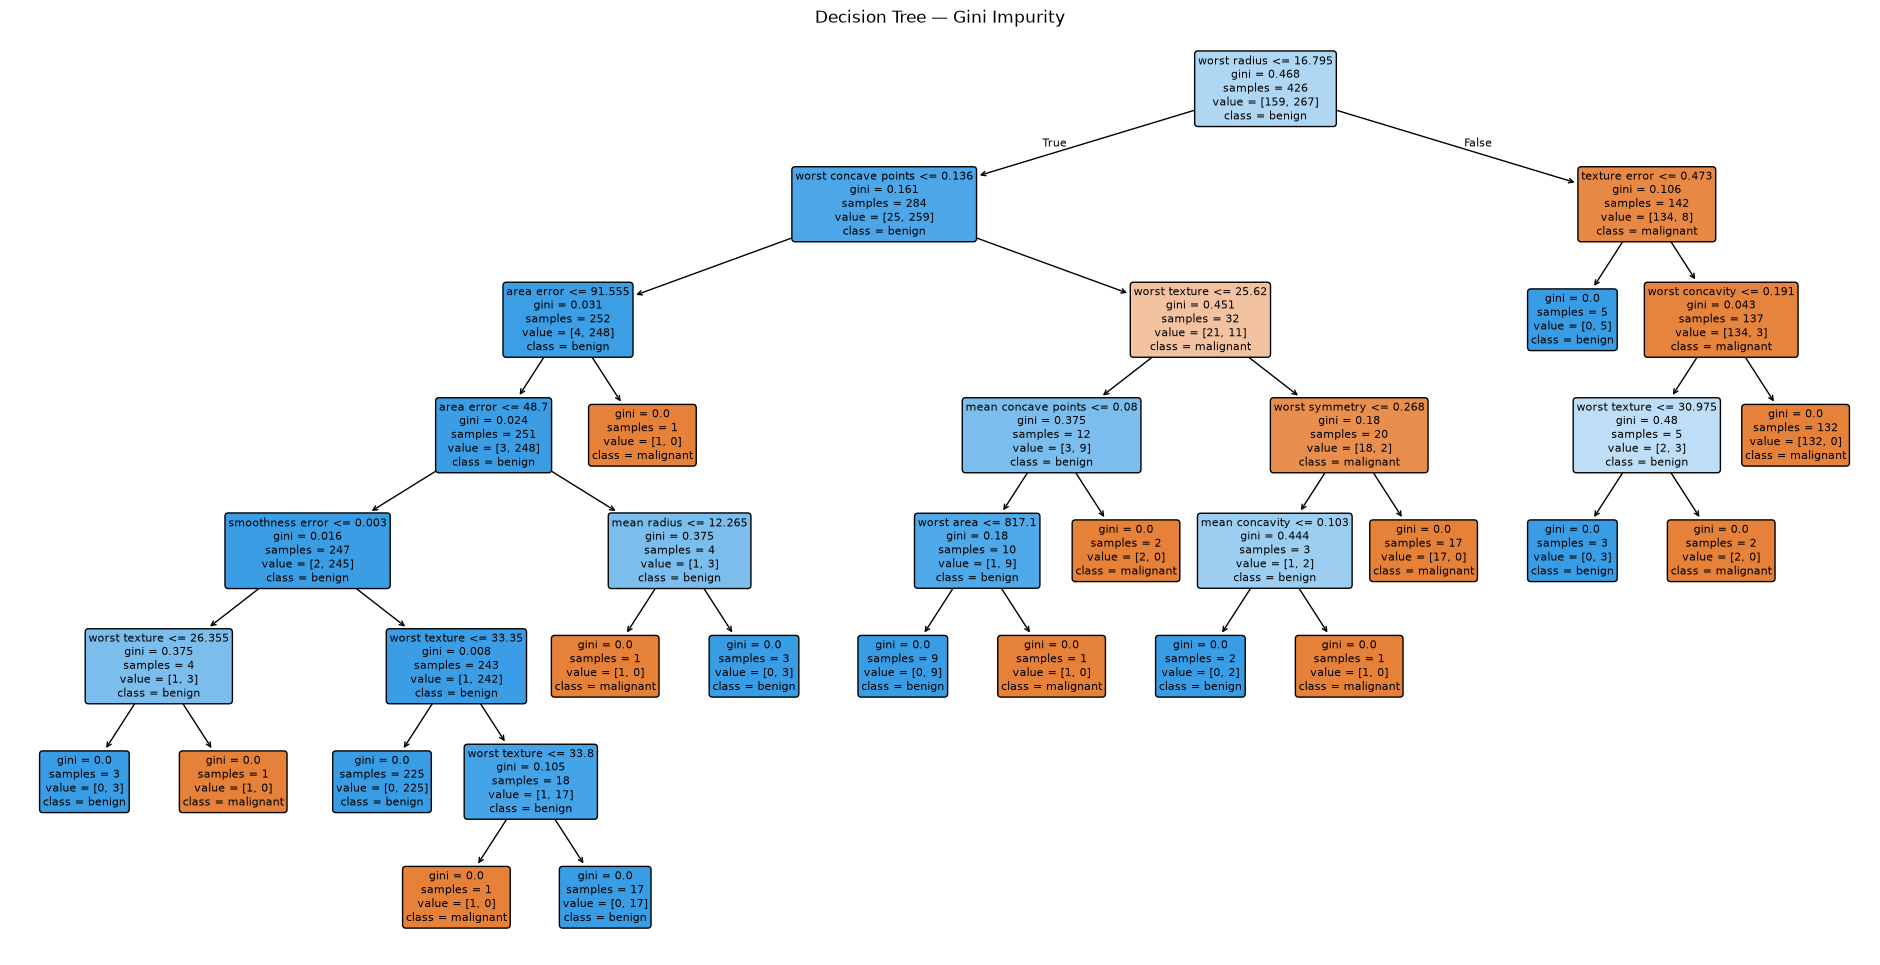

Tree depth: 7
Number of leaves: 18


In [8]:
plt.figure(figsize=(24, 12))
plot_tree(
    tree_gini,
    feature_names=data.feature_names,
    class_names=data.target_names,
    filled=True,
    rounded=True,
    fontsize=8
)
plt.title("Decision Tree — Gini Impurity")
plt.show()

print("Tree depth:", tree_gini.get_depth())
print("Number of leaves:", tree_gini.get_n_leaves())


### Questions — Activity 3

1. What feature is used at the root (top) of the tree?
2. What threshold does the root node use?
3. How many levels deep is the tree? How many leaf nodes does it have?
4. Pick one test observation. Trace the feature comparisons from the root to a leaf. What class does the tree predict?
5. Does a high training accuracy guarantee that the model will perform well on new data? Why or why not?

**Your answers:**

1. Worst radius
2. Greater than 16.795
3. 7 levels deep with 18 leaves
4. benign
5. A high traning accuracy may be inaccurate if the model is overfitted, which will result in worse predictions for someone that doesnt follow the tree correctly


In [9]:
# Optional helper: inspect one test observation and its prediction.
sample_position = 0
sample = X_test.iloc[[sample_position]]

print("Actual class:", data.target_names[int(y_test.iloc[sample_position])])
print("Predicted class:", data.target_names[int(tree_gini.predict(sample)[0])])
display(sample)


Actual class: benign
Predicted class: benign


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
519,12.75,16.7,82.51,493.8,0.1125,0.1117,0.0388,0.02995,0.212,0.06623,...,14.45,21.74,93.63,624.1,0.1475,0.1979,0.1423,0.08045,0.3071,0.08557


## Activity 4 — Compare Gini impurity and entropy

Scikit-learn supports both criteria. Train one tree with each criterion using the same training data and random state. Compare their performance and structure.

The two criteria often produce similar trees, but they are not guaranteed to select identical splits.


In [10]:
models_by_criterion = {}

for criterion in ["gini", "entropy"]:
    model = DecisionTreeClassifier(
        criterion=criterion,
        random_state=RANDOM_STATE
    )
    model.fit(X_train, y_train)
    models_by_criterion[criterion] = model

    print(f"Criterion: {criterion}")
    print("  Training accuracy:", model.score(X_train, y_train))
    print("  Test accuracy:", model.score(X_test, y_test))
    print("  Depth:", model.get_depth())
    print("  Leaves:", model.get_n_leaves())


Criterion: gini
  Training accuracy: 1.0
  Test accuracy: 0.9230769230769231
  Depth: 7
  Leaves: 18
Criterion: entropy
  Training accuracy: 1.0
  Test accuracy: 0.9300699300699301
  Depth: 6
  Leaves: 15


### Questions — Activity 4

1. Did Gini and entropy produce trees with the same depth and number of leaves?
2. Did one criterion achieve higher test accuracy?
3. Does a small difference in accuracy mean one criterion is always better? Why is it important to evaluate on more than one split?

**Your answers:**

1. No
2. Entropy had higher test accuracy by a percentage
3. A small difference in accuracy doesn't mean either criterion is better due to random outcomes. Evaluating more than 1 split is better because it allows you to generalize the model


## Activity 5 — Investigate overfitting

A decision tree can keep splitting until it creates very specific rules for the training observations. A deep tree may achieve nearly perfect training accuracy while performing less well on unseen data. This is **overfitting**.

The `max_depth` parameter limits the number of levels in the tree. We will train trees with different maximum depths and compare training and test accuracy.


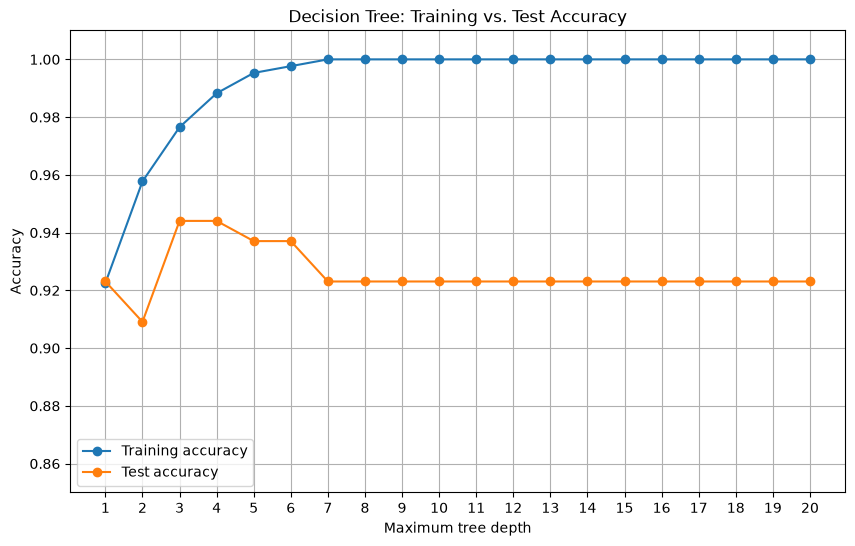

In [11]:
depths = range(1, 21)
train_scores = []
test_scores = []

for depth in depths:
    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=RANDOM_STATE
    )
    model.fit(X_train, y_train)

    train_scores.append(model.score(X_train, y_train))
    test_scores.append(model.score(X_test, y_test))

plt.figure(figsize=(10, 6))
plt.plot(depths, train_scores, marker="o", label="Training accuracy")
plt.plot(depths, test_scores, marker="o", label="Test accuracy")
plt.xlabel("Maximum tree depth")
plt.ylabel("Accuracy")
plt.title("Decision Tree: Training vs. Test Accuracy")
plt.xticks(list(depths))
plt.ylim(0.85, 1.01)
plt.grid(True)
plt.legend()
plt.show()


### Questions — Activity 5

1. At what depth does training accuracy first reach 100%, if it does?
2. Does test accuracy keep increasing as depth increases?
3. Identify a depth where the gap between training and test accuracy suggests overfitting.
4. Why can a tree with perfect training accuracy perform worse on new data?
5. Based on this experiment, would you choose the deepest tree? Explain.

**Your answers:**

1. At depth 7
2. It does not as it stagnates around depth 7
3. Probably at depth 7 since it stops improving
4. It suggests the tree is overfitted
5. Probably not, since at a certain point the test accuracy is worse off than the training accuracy would suggest


## Activity 6 — Control complexity with pruning

Limiting maximum depth is one way to control a tree's complexity. Another is **cost-complexity pruning**.

The pruning objective can be written as:

\[
R_\alpha(T) = R(T) + \alpha |T|
\]

Here, \(R(T)\) represents the tree's total leaf error (as defined by the pruning procedure), \(|T|\) is the number of terminal leaves, and \(\alpha\) controls the penalty for tree complexity. Larger values of `ccp_alpha` generally produce smaller trees.

We will compare several values. The best value depends on the data and should be selected using validation or cross-validation rather than by repeatedly optimizing against the final test set.


In [12]:
alphas = [0.0, 0.0001, 0.0005, 0.001, 0.002, 0.005, 0.01, 0.02]

pruning_results = []

for alpha in alphas:
    model = DecisionTreeClassifier(
        ccp_alpha=alpha,
        random_state=RANDOM_STATE
    )
    model.fit(X_train, y_train)

    pruning_results.append({
        "ccp_alpha": alpha,
        "depth": model.get_depth(),
        "leaves": model.get_n_leaves(),
        "training_accuracy": model.score(X_train, y_train),
        "test_accuracy": model.score(X_test, y_test)
    })

pruning_df = pd.DataFrame(pruning_results)
display(pruning_df)


,ccp_alpha,depth,leaves,training_accuracy,test_accuracy
0,0.0000,7,18,1.000000,0.923077
1,0.0001,7,18,1.000000,0.923077
2,0.0005,7,18,1.000000,0.923077
3,0.0010,7,18,1.000000,0.923077
4,0.0020,7,18,1.000000,0.923077
5,0.0050,4,9,0.985915,0.944056
6,0.0100,3,5,0.971831,0.944056
7,0.0200,2,4,0.957746,0.909091


### Cross-validation for a more reliable comparison

A single train/test split can give a noisy estimate of model performance. Cross-validation repeatedly trains and evaluates models on different partitions of the training data. Here, we use five-fold cross-validation on the training set to compare pruning values.

The held-out test set remains separate for the final evaluation.


In [13]:
cv_results = []

for alpha in alphas:
    model = DecisionTreeClassifier(
        ccp_alpha=alpha,
        random_state=RANDOM_STATE
    )
    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring="accuracy"
    )
    cv_results.append({
        "ccp_alpha": alpha,
        "mean_cv_accuracy": scores.mean(),
        "std_cv_accuracy": scores.std()
    })

cv_df = pd.DataFrame(cv_results)
display(cv_df.sort_values("mean_cv_accuracy", ascending=False))


,ccp_alpha,mean_cv_accuracy,std_cv_accuracy
5,0.0050,0.936717,0.023796
0,0.0000,0.929685,0.028373
1,0.0001,0.929685,0.028373
2,0.0005,0.929685,0.028373
3,0.0010,0.929685,0.028373
4,0.0020,0.929685,0.028373
6,0.0100,0.924979,0.023748
7,0.0200,0.920301,0.031453


### Select and evaluate a pruned model

Choose the `ccp_alpha` with the highest mean cross-validation accuracy. If several values are very close, consider preferring the simpler tree. Fit that model on the full training set and evaluate it once on the held-out test set.


In [14]:
best_alpha = cv_df.loc[cv_df["mean_cv_accuracy"].idxmax(), "ccp_alpha"]

pruned_tree = DecisionTreeClassifier(
    ccp_alpha=float(best_alpha),
    random_state=RANDOM_STATE
)
pruned_tree.fit(X_train, y_train)

print("Selected ccp_alpha:", best_alpha)
print("Tree depth:", pruned_tree.get_depth())
print("Number of leaves:", pruned_tree.get_n_leaves())
print("Training accuracy:", pruned_tree.score(X_train, y_train))
print("Held-out test accuracy:", pruned_tree.score(X_test, y_test))


Selected ccp_alpha: 0.005
Tree depth: 4
Number of leaves: 9
Training accuracy: 0.9859154929577465
Held-out test accuracy: 0.9440559440559441


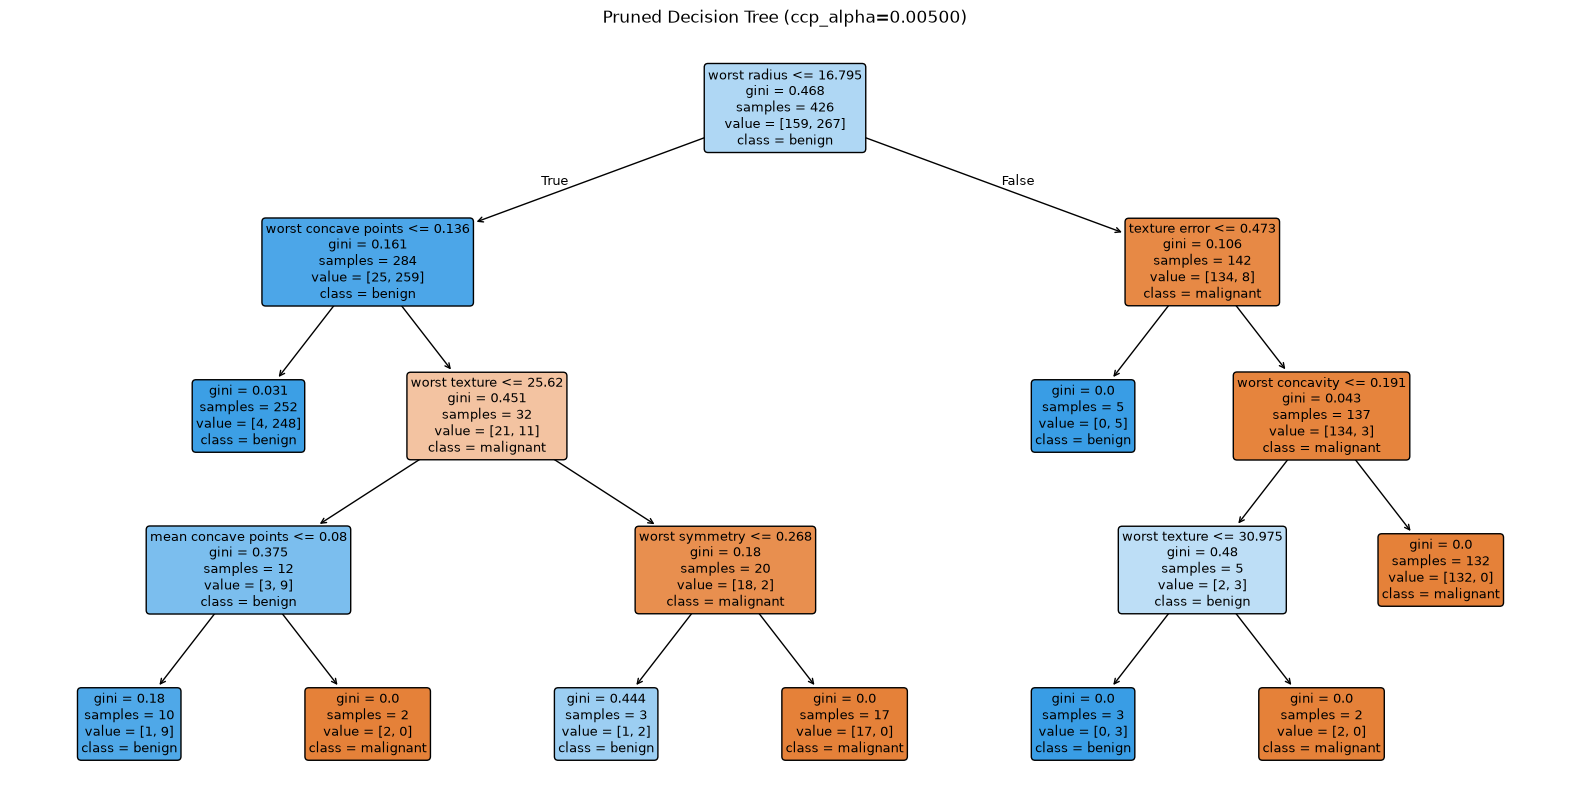

In [15]:
plt.figure(figsize=(20, 10))
plot_tree(
    pruned_tree,
    feature_names=data.feature_names,
    class_names=data.target_names,
    filled=True,
    rounded=True,
    fontsize=9
)
plt.title(f"Pruned Decision Tree (ccp_alpha={best_alpha:.5f})")
plt.show()


### Questions — Activity 6

1. As `ccp_alpha` increases, what generally happens to tree depth and number of leaves?
2. Does pruning always improve test accuracy?
3. Why use cross-validation to choose a pruning value?
4. Which model would you choose: the most accurate model, the simplest model, or a compromise? Defend your choice using your results.
5. Why should the final test set not be used repeatedly to choose hyperparameters?

**Your answers:**

1. tree depth and leaves decrease
2. It improves test accuracy up to a certain point where it starts to get worse due to less context
3. Cross validation tests from multiple parts of the training data to paint a more accurate picture of using the pruning
4. I would use a comprimse between high but not perfect training accuracy and a reasonable depth to ensure the best test accuracy. The
best test accuracy came from the tree which was in a sweet spot.
5. The final test set should not be used repeatedly to choose hyperparameters because it can lead to overfitting on the test set, giving an overly optimistic estimate of model performance.


## Activity 7 — Feature importance and model interpretation

Decision trees can report feature importance scores. In scikit-learn, these scores are based on the total (weighted) reduction in the splitting criterion attributable to each feature across the tree, then normalized to sum to 1.

Feature importance can help summarize which features the tree used. However, it does **not** establish that a feature causes the outcome. Importance can also be distributed among correlated features, and impurity-based importance can favor some kinds of features.

We will inspect the most important features in the pruned tree.


,importance
worst radius,0.736113
worst concave points,0.123673
texture error,0.049016
worst texture,0.046401
worst concavity,0.018420
mean concave points,0.014339
worst symmetry,0.012037
mean radius,0.000000
concavity error,0.000000
worst compactness,0.000000


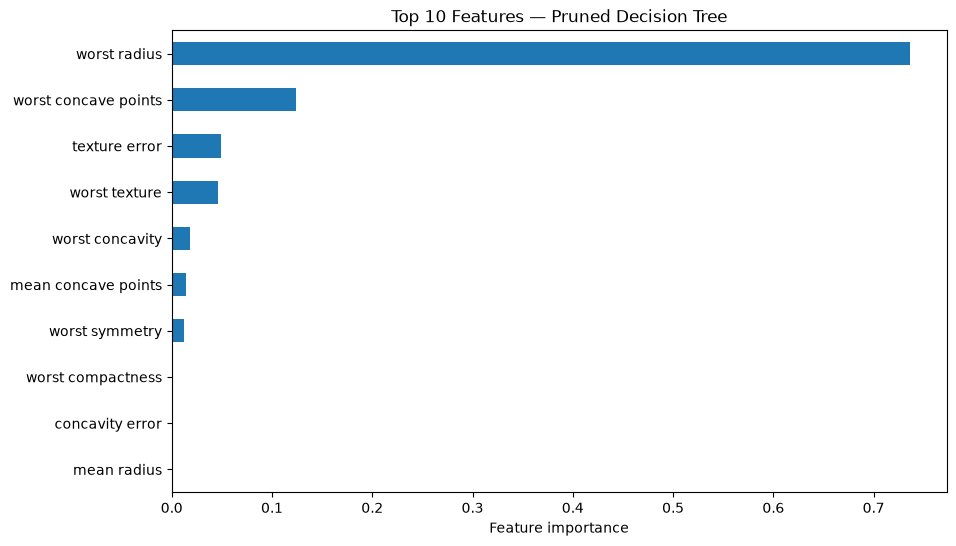

In [16]:
importance = pd.Series(
    pruned_tree.feature_importances_,
    index=data.feature_names
).sort_values(ascending=False)

display(importance.head(10).to_frame("importance"))

top_importance = importance.head(10).sort_values()
plt.figure(figsize=(10, 6))
top_importance.plot(kind="barh")
plt.xlabel("Feature importance")
plt.title("Top 10 Features — Pruned Decision Tree")
plt.show()


### Questions — Activity 7

1. Which three features have the highest importance in your model?
2. Are these the same features you predicted would matter in Activity 1?
3. What does a feature importance score tell you?
4. Why should you not interpret feature importance as proof of causation?
5. What might happen to importance scores when two features are strongly correlated?

**Your answers:**

1. worst radius, worst concave points, texture error
2. No
3. It tells me that the certain feature has more prevalence in the data set compared to the others
4. It is not proof of causation because it is only a measure of how much the feature was used in the model, not whether it caused the outcome
5. It might skew the test accuracy for all observations without the features strongly in favor


## Activity 8 — Evaluate errors, not just accuracy

Accuracy is the fraction of predictions that are correct. It is useful, but it does not tell us which kinds of mistakes the model makes.

A **confusion matrix** compares actual classes with predicted classes. A false negative in this lab means a malignant sample was predicted to be benign. A false positive means a benign sample was predicted to be malignant.

For a medical screening context, a false negative can be especially concerning. This is why recall for the malignant class may matter more than accuracy alone. The appropriate tradeoff depends on the real-world setting; this classroom model is not suitable for clinical use.


              precision    recall  f1-score   support

   malignant       0.92      0.92      0.92        53
      benign       0.96      0.96      0.96        90

    accuracy                           0.94       143
   macro avg       0.94      0.94      0.94       143
weighted avg       0.94      0.94      0.94       143



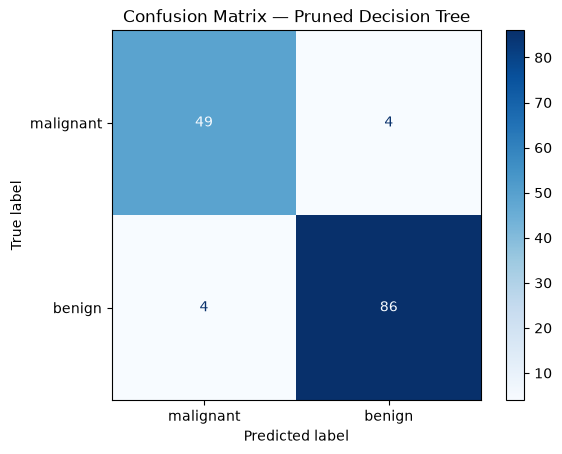

In [17]:
final_predictions = pruned_tree.predict(X_test)

print(classification_report(
    y_test,
    final_predictions,
    target_names=data.target_names
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    final_predictions,
    display_labels=data.target_names,
    cmap="Blues"
)
plt.title("Confusion Matrix — Pruned Decision Tree")
plt.show()


### Questions — Activity 8

1. What is the model's accuracy on the held-out test set?
2. What is precision? What is recall?
3. In this dataset, which class corresponds to a malignant sample?
4. How many malignant samples were incorrectly classified as benign?
5. Why might recall for the malignant class be particularly important in a screening context?
6. Could a model have high accuracy but still be unsuitable for this task? Explain.

**Your answers:**

1. 94 percent
2. Precision is the fraction of positive predictions that are correct. Recall is the fraction of actual positives that are correctly predicted.
3. The malignant class corresponds to the positive class
4. 4 malignant samples were incorrectly classified as benign
5. recall for the malignant class would be important since it would be impoortant to catch all of the malignant cases and prevent false negatives
6. Yes because if a model still detects false negatives, it could be unsuitable for the task since it would be life or death.

## Activity 9 — Advanced challenges

Complete one or more of these challenges if time permits, or use them as follow-up assignments.

### Challenge A: Change the train/test split

Change `test_size` or `random_state` in Activity 3. Retrain the model. How much do its accuracy, root feature, depth, and number of leaves change?

### Challenge B: Restrict the features

Train a tree using only five features of your choice. Compare its performance and complexity with the tree that uses all 30 features. Explain how you selected the five.

### Challenge C: Change other complexity parameters

Experiment with `min_samples_split` and `min_samples_leaf`. How do they affect tree size and generalization?

Example:

```python
DecisionTreeClassifier(
    max_depth=5,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=RANDOM_STATE
)
```

### Challenge D: Compare a single tree with a random forest

A random forest trains many decision trees on different samples and combines their predictions. Compare a single decision tree with a random forest. What happens to predictive performance and interpretability?

### Challenge E: Investigate model stability

Train trees using several random seeds or different training subsets. Compare their root features and structures. If the trees differ, what does that suggest about the stability of a decision tree explanation?

### Challenge F: Gini versus entropy beyond accuracy

Compare the structures of Gini and entropy trees. Do they make the same predictions? Are their most important features the same? Explain why similar performance does not necessarily imply identical models.


## Final reflection

Write a short conclusion (approximately 200–300 words) addressing the following:

1. How does a decision tree choose a split?
2. What is the difference between Gini impurity and entropy?
3. What evidence of overfitting did you observe?
4. How did pruning affect model complexity and performance?
5. What are the main advantages and limitations of decision trees?
6. In what situations might you prefer a decision tree over a more complex model?

## Myanswer
A decision tree chooses a split based on what it would percieve to be the more balanced option. For example, it would
rather choose a split of 5 and 5 of the same rather than 4 and 1 of one and 1 and 4 of the other, in order to keep 
purity. The difference between purity and entropy is that purity is how much of the node is uniform where as entropy measure how non uniform the node is. I saw overfitting when I was investigating pruning, and it was due to the training accuracy being 100 percent.
In this way, the pruning had a positive affect on test accuracy up to a certain point where it was pruned too far. The advantages
of a decision tree is that its good at making a prediction when the observations follow the tree in an expected way. In the same way the limitation is that if the observation goes a different way than expected towards the end, it may not be caught since there are no samples for the node if the tree is pure. Decision trees may be good for a survey use case.

## Submission checklist

- [ ] All notebook cells have been run.
- [ ] Activities 1–8 include written answers.
- [ ] The notebook includes the requested visualizations.
- [ ] The final reflection is complete.
- [ ] I can explain impurity, entropy, information gain, and overfitting in my own words.
